# Hipótese 2: Alarme em portas + usadas(extremos ou meio)

## 1. Contexto e Fundamentação Teórica
As Portas de Plataforma (PSDs) são equipamentos de segurança distribuídos ao longo das plataformas e submetidos continuamente à interação com os passageiros durante o embarque e o desembarque. Embora todas realizem ciclos de abertura e fechamento, sua localização pode gerar diferentes níveis de exposição ao fluxo de pessoas. Portas próximas a escadas, escadas rolantes, elevadores e acessos à plataforma tendem a receber maior concentração de passageiros do que aquelas situadas em regiões mais afastadas.

A maior interação com passageiros pode aumentar tanto a ocorrência de obstáculos durante o movimento das folhas quanto o desgaste dos componentes mecânicos e eletrônicos das portas. Consequentemente, portas mais utilizadas podem apresentar maior frequência de diferentes alarmes e defeitos, como obstáculos (`OBS`), esforço excessivo, tempos excedidos de abertura ou fechamento e falhas relacionadas aos sensores.

A hipótese operacional deste estudo estabelece, portanto, que a posição da porta na plataforma está associada à frequência de alarmes e defeitos, com expectativa de maior incidência nas portas mais utilizadas, geralmente próximas ao centro ou aos acessos em comparação às portas menos utilizadas, localizadas nas extremidades. A análise contemplará os diferentes tipos de alarme vinculados a cada porta. Especificamente para os registros `OBS`, que representam obstáculos, serão consideradas apenas ocorrências com duração superior a 60 segundos; registros `OBS` com duração igual ou inferior a 60 segundos, ausente ou inválida serão desconsiderados. Esse filtro não será aplicado aos demais tipos de alarme.

Como a base não contém medições diretas do fluxo de passageiros nem a localização dos acessos de cada estação, a posição geométrica da porta será utilizada como aproximação de uso. Dessa forma, os resultados permitirão identificar associações entre posição e frequência de alarmes, mas não comprovar, isoladamente, que o fluxo de passageiros é a causa direta dos defeitos encontrados.

---

## 2. Importação das bibliotecas e auditoria inicial

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

alarmes_path = "../../data/Alarmes do sistema de PSD.xlsx"
df_alarmes = pd.read_excel(alarmes_path)

print(f"Dimensão da base: {df_alarmes.shape[0]:,} linhas × {df_alarmes.shape[1]} colunas")
display(df_alarmes.head())

Dimensão da base: 150,003 linhas × 7 colunas


,TAG,Horário do Alarme,Estação,Porta,Alarme,Horário da Normalizacao,Tempo de Normalização
0,PSD_FAL_FAL2_PDM09_OBS,2026-05-12 08:16:52.657,FAL,9.0,OBS,2026-05-12 08:16:53.670,"0 dias, 00:00:01"
1,PSD_LUZ_LUZ1_PDM08_OBS,2026-05-12 08:15:09.913,LUZ,8.0,OBS,2026-05-12 08:15:10.917,"0 dias, 00:00:01"
2,PSD_FAL_FAL1_PDM15_OBS,2026-05-12 08:14:06.657,FAL,15.0,OBS,2026-05-12 08:14:07.670,"0 dias, 00:00:01"
3,PSD_LUZ_LUZ1_PDM19_OBS,2026-05-12 08:09:31.930,LUZ,19.0,OBS,2026-05-12 08:09:32.917,"0 dias, 00:00:01"
4,PSD_FRE_FRE1_PDM14_OBS,2026-05-12 08:05:05.830,FRE,14.0,OBS,2026-05-12 08:05:14.847,"0 dias, 00:00:09"


In [5]:
# Auditoria inicial da base, sem alterar ou excluir registros
resumo_colunas = pd.DataFrame({
    "tipo": df_alarmes.dtypes.astype(str),
    "valores_ausentes": df_alarmes.isna().sum(),
    "percentual_ausente": (df_alarmes.isna().mean() * 100).round(2),
    "valores_unicos": df_alarmes.nunique(dropna=True),
})

print(f"Duplicatas exatas: {df_alarmes.duplicated().sum():,}")
display(resumo_colunas)

Duplicatas exatas: 0


,tipo,valores_ausentes,percentual_ausente,valores_unicos
TAG,str,1,0.00,379
Horário do Alarme,datetime64[us],37252,24.83,36477
Estação,str,3,0.00,6
Porta,float64,3,0.00,24
Alarme,str,3,0.00,8
Horário da Normalizacao,datetime64[us],3,0.00,35360
Tempo de Normalização,str,3,0.00,56673


## 3. Pré-processamento e Limpeza dos Dados

A base não possui duplicatas exatas, mas contém registros sem horário de alarme e três linhas sem identificação de estação, porta e tipo de alarme. Nesta etapa, os dados serão tratados sem modificar a base original. As regras de duração serão aplicadas apenas aos alarmes de obstáculo (`OBS`); os demais tipos de alarme serão preservados para a análise.

In [6]:
# Cópia de trabalho para preservar a base original
df = df_alarmes.copy()

colunas_identificacao = ["Estação", "Porta", "Alarme"]
linhas_sem_identificacao = df[colunas_identificacao].isna().any(axis=1)

print(f"Linhas sem identificação removidas: {linhas_sem_identificacao.sum():,}")
display(df.loc[linhas_sem_identificacao])

df = df.loc[~linhas_sem_identificacao].copy().reset_index(drop=True)

print(f"Dimensão após a remoção: {df.shape[0]:,} linhas × {df.shape[1]} colunas")

Linhas sem identificação removidas: 3


,TAG,Horário do Alarme,Estação,Porta,Alarme,Horário da Normalizacao,Tempo de Normalização
150000,NaN,NaT,NaN,NaN,NaN,NaT,NaN
150001,Nenhum filtro aplicado,NaT,NaN,NaN,NaN,NaT,NaN
150002,Exported data exceeded the allowed volume. Som...,NaT,NaN,NaN,NaN,NaT,NaN


Dimensão após a remoção: 150,000 linhas × 7 colunas


In [7]:
# Padronização dos tipos e cálculo da duração dos alarmes
df["TAG"] = df["TAG"].astype("string").str.strip().str.upper()
df["Estação"] = df["Estação"].astype("string").str.strip().str.upper()
df["Alarme"] = df["Alarme"].astype("string").str.strip().str.upper()
df["Porta"] = pd.to_numeric(df["Porta"], errors="coerce").astype("Int64")
df["Horário do Alarme"] = pd.to_datetime(df["Horário do Alarme"], errors="coerce")
df["Horário da Normalizacao"] = pd.to_datetime(
    df["Horário da Normalizacao"], errors="coerce"
)

df["Duração em segundos"] = (
    df["Horário da Normalizacao"] - df["Horário do Alarme"]
).dt.total_seconds()

print(f"Durações ausentes: {df['Duração em segundos'].isna().sum():,}")
display(df.dtypes.rename("tipo").to_frame())
display(df.head())

Durações ausentes: 37,249


,tipo
TAG,string
Horário do Alarme,datetime64[us]
Estação,string
Porta,Int64
Alarme,string
Horário da Normalizacao,datetime64[us]
Tempo de Normalização,str
Duração em segundos,float64


,TAG,Horário do Alarme,Estação,Porta,Alarme,Horário da Normalizacao,Tempo de Normalização,Duração em segundos
0,PSD_FAL_FAL2_PDM09_OBS,2026-05-12 08:16:52.657,FAL,9,OBS,2026-05-12 08:16:53.670,"0 dias, 00:00:01",1.013
1,PSD_LUZ_LUZ1_PDM08_OBS,2026-05-12 08:15:09.913,LUZ,8,OBS,2026-05-12 08:15:10.917,"0 dias, 00:00:01",1.004
2,PSD_FAL_FAL1_PDM15_OBS,2026-05-12 08:14:06.657,FAL,15,OBS,2026-05-12 08:14:07.670,"0 dias, 00:00:01",1.013
3,PSD_LUZ_LUZ1_PDM19_OBS,2026-05-12 08:09:31.930,LUZ,19,OBS,2026-05-12 08:09:32.917,"0 dias, 00:00:01",0.987
4,PSD_FRE_FRE1_PDM14_OBS,2026-05-12 08:05:05.830,FRE,14,OBS,2026-05-12 08:05:14.847,"0 dias, 00:00:09",9.017


In [8]:
# Filtro específico para alarmes de obstáculo (OBS)
eh_obs = df["Alarme"].eq("OBS")
obs_acima_60s = eh_obs & df["Duração em segundos"].gt(60)
outros_alarmes = ~eh_obs

df_filtrado = df.loc[obs_acima_60s | outros_alarmes].copy().reset_index(drop=True)

resumo_filtro_obs = pd.DataFrame({
    "Registros": [
        obs_acima_60s.sum(),
        (eh_obs & df["Duração em segundos"].le(60)).sum(),
        (eh_obs & df["Duração em segundos"].isna()).sum(),
        outros_alarmes.sum(),
        len(df_filtrado),
    ]
}, index=[
    "OBS mantidos (> 60 s)",
    "OBS removidos (≤ 60 s)",
    "OBS removidos (sem duração)",
    "Demais alarmes mantidos",
    "Total após o filtro",
])

display(resumo_filtro_obs)

,Registros
OBS mantidos (> 60 s),54424
OBS removidos (≤ 60 s),28058
OBS removidos (sem duração),28638
Demais alarmes mantidos,38880
Total após o filtro,93304


In [9]:
# Extração dos identificadores presentes na TAG
partes_tag = df_filtrado["TAG"].str.extract(
    r"_(?P<Estacao_TAG>[A-Z]{3})(?P<Via>[12])_"
    r"(?P<Componente>PDM|MDU)(?P<Porta_TAG>\d{1,2})_"
)

df_filtrado["Estacao_TAG"] = partes_tag["Estacao_TAG"]
df_filtrado["Via"] = partes_tag["Via"].astype("Int64")
df_filtrado["Componente"] = partes_tag["Componente"]
df_filtrado["Porta_TAG"] = pd.to_numeric(
    partes_tag["Porta_TAG"], errors="coerce"
).astype("Int64")

portas_divergentes = (
    df_filtrado["Porta_TAG"].notna()
    & df_filtrado["Porta"].ne(df_filtrado["Porta_TAG"])
).sum()

print(f"TAGs não interpretadas: {df_filtrado['Componente'].isna().sum():,}")
print(f"Divergências entre Porta e Porta_TAG: {portas_divergentes:,}")
display(pd.crosstab(df_filtrado["Componente"], df_filtrado["Alarme"], margins=True))

TAGs não interpretadas: 0
Divergências entre Porta e Porta_TAG: 0


Alarme,CA,CSD,FC,FO,LSD,OA,OBS,STS,All
Componente,,,,,,,,,
MDU,0,0,0,0,0,0,0,12822,12822
PDM,4168,4102,4437,4617,4606,4128,54424,0,80482
All,4168,4102,4437,4617,4606,4128,54424,12822,93304


In [10]:
# Seleção dos alarmes vinculados diretamente às portas (PDM)
df_portas = (
    df_filtrado.loc[df_filtrado["Componente"].eq("PDM")]
    .copy()
    .reset_index(drop=True)
)

print(f"Registros MDU/STS removidos: {len(df_filtrado) - len(df_portas):,}")
print(f"Registros PDM mantidos: {len(df_portas):,}")
display(df_portas["Alarme"].value_counts().rename("Registros").to_frame())

Registros MDU/STS removidos: 12,822
Registros PDM mantidos: 80,482


,Registros
Alarme,
OBS,54424
FO,4617
LSD,4606
FC,4437
CA,4168
OA,4128
CSD,4102


In [11]:
# Identificação da plataforma e de cada porta física
df_portas["Plataforma_ID"] = (
    df_portas["Estação"]
    + "_V"
    + df_portas["Via"].astype("string")
)
df_portas["Porta_ID"] = (
    df_portas["Plataforma_ID"]
    + "_PDM"
    + df_portas["Porta"].astype("string").str.zfill(2)
)

print(f"Plataformas identificadas: {df_portas['Plataforma_ID'].nunique()}")
print(f"Portas físicas identificadas: {df_portas['Porta_ID'].nunique()}")
display(df_portas[["Estação", "Via", "Porta", "Plataforma_ID", "Porta_ID"]].head())

Plataformas identificadas: 12
Portas físicas identificadas: 257


,Estação,Via,Porta,Plataforma_ID,Porta_ID
0,BUT,1,7,BUT_V1,BUT_V1_PDM07
1,BUT,1,4,BUT_V1,BUT_V1_PDM04
2,FRE,1,4,FRE_V1,FRE_V1_PDM04
3,FRE,1,6,FRE_V1,FRE_V1_PDM06
4,BUT,1,9,BUT_V1,BUT_V1_PDM09


## 4. Análise Exploratória dos Alarmes por Porta

Nesta etapa, será analisada a quantidade de ocorrências válidas registrada por porta física. A comparação será feita por estação e via, preservando o tipo de alarme para permitir tanto a análise geral dos defeitos quanto análises específicas, como a de obstáculos (`OBS`).


In [12]:
# Ranking das portas pela quantidade de ocorrências válidas
ranking_portas = (
    df_portas.groupby(
        ["Porta_ID", "Estação", "Via", "Porta"],
        as_index=False,
        observed=True,
    )
    .agg(
        Total_Alarmes=("Alarme", "size"),
        Tipos_Alarme=("Alarme", "nunique"),
        Primeiro_Alarme=("Horário do Alarme", "min"),
        Ultimo_Alarme=("Horário do Alarme", "max"),
    )
    .sort_values(
        ["Total_Alarmes", "Porta_ID"],
        ascending=[False, True],
    )
    .reset_index(drop=True)
)

print(f"Portas presentes no ranking: {len(ranking_portas):,}")
display(ranking_portas.head(20))

Portas presentes no ranking: 257


,Porta_ID,Estação,Via,Porta,Total_Alarmes,Tipos_Alarme,Primeiro_Alarme,Ultimo_Alarme
0,BUT_V1_PDM07,BUT,1,7,2935,7,2023-12-02 14:37:36.417,2026-05-11 18:55:45.703
1,BUT_V1_PDM10,BUT,1,10,2777,7,2023-11-10 15:42:04.927,2026-04-01 09:15:30.030
2,BUT_V1_PDM05,BUT,1,5,2508,7,2023-12-15 07:09:45.817,2026-02-27 17:15:41.637
3,BUT_V1_PDM09,BUT,1,9,2502,7,2023-10-24 12:10:09.353,2026-05-05 17:35:17.143
4,BUT_V1_PDM08,BUT,1,8,2466,7,2023-11-10 18:42:34.927,2026-04-26 14:16:22.650
5,BUT_V1_PDM06,BUT,1,6,2463,7,2023-11-30 08:59:01.727,2026-02-10 20:42:41.893
6,BUT_V1_PDM02,BUT,1,2,2449,7,2023-10-28 11:51:43.630,2026-04-07 12:27:18.627
7,BUT_V1_PDM04,BUT,1,4,2436,7,2023-12-21 16:00:44.370,2026-05-10 05:02:52.937
8,BUT_V1_PDM01,BUT,1,1,2429,7,2024-01-21 23:12:46.257,2026-04-04 14:47:54.940
9,BUT_V1_PDM11,BUT,1,11,2337,7,2024-03-11 09:45:41.557,2026-03-28 08:37:04.317


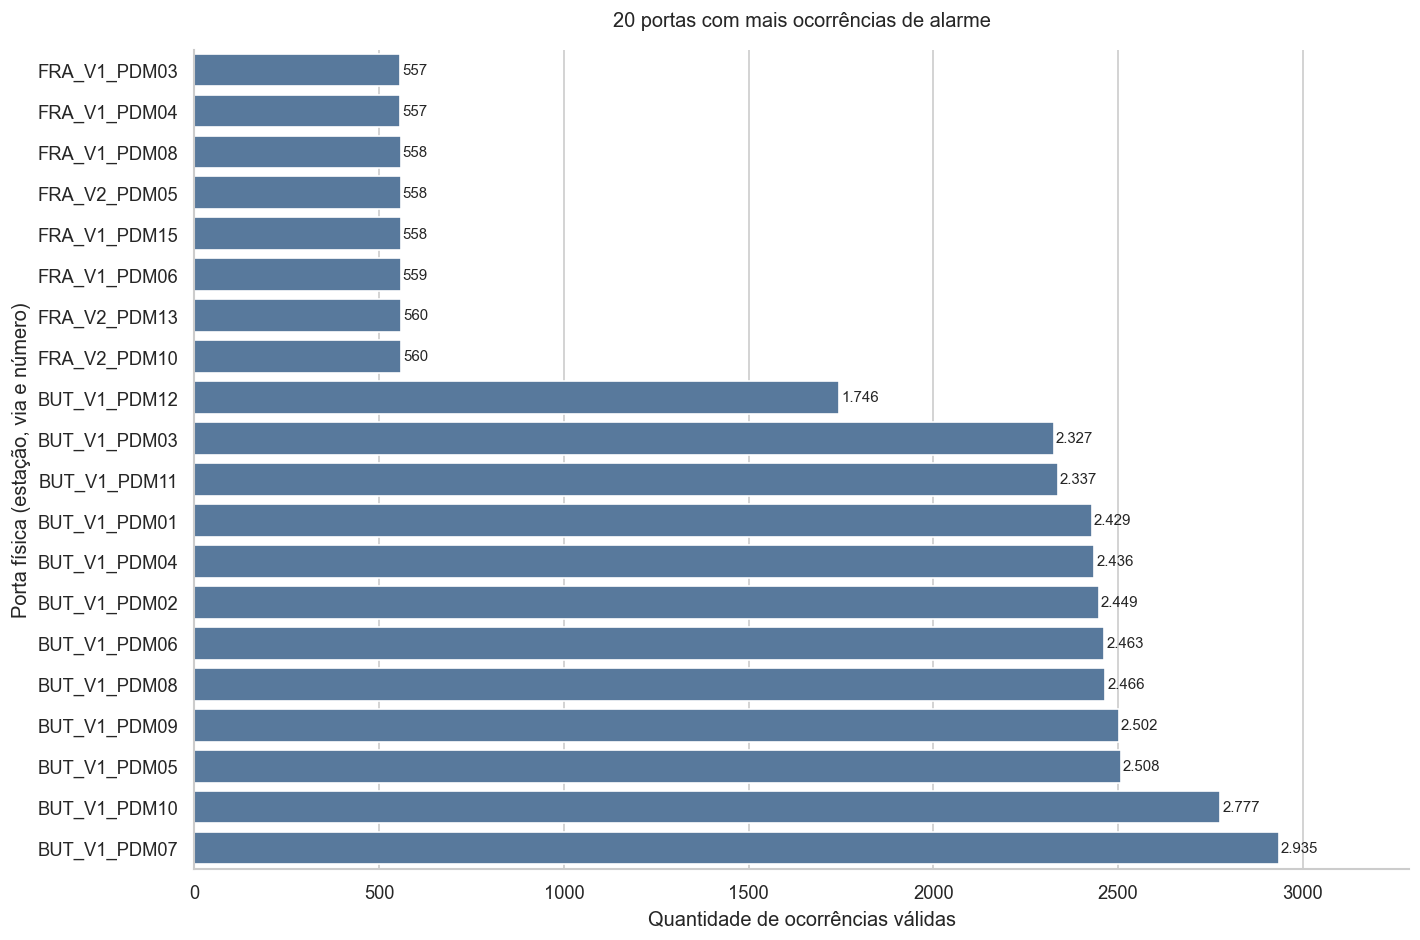

In [13]:
# Visualização das 20 portas com mais ocorrências válidas
top_20_portas = ranking_portas.head(20).sort_values("Total_Alarmes")

fig, ax = plt.subplots(figsize=(12, 8))
sns.barplot(
    data=top_20_portas,
    x="Total_Alarmes",
    y="Porta_ID",
    color="#4C78A8",
    ax=ax,
)

for barra in ax.patches:
    valor = int(barra.get_width())
    ax.text(
        barra.get_width() + 5,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:,}".replace(",", "."),
        va="center",
        fontsize=9,
    )

ax.set_title("20 portas com mais ocorrências de alarme", pad=14)
ax.set_xlabel("Quantidade de ocorrências válidas")
ax.set_ylabel("Porta física (estação, via e número)")
ax.set_xlim(0, top_20_portas["Total_Alarmes"].max() * 1.12)
sns.despine()
plt.tight_layout()
plt.show()